✅ Preprocessing Complete
Training Data Shape: (23624, 5)
Testing Data Shape: (5907, 5)


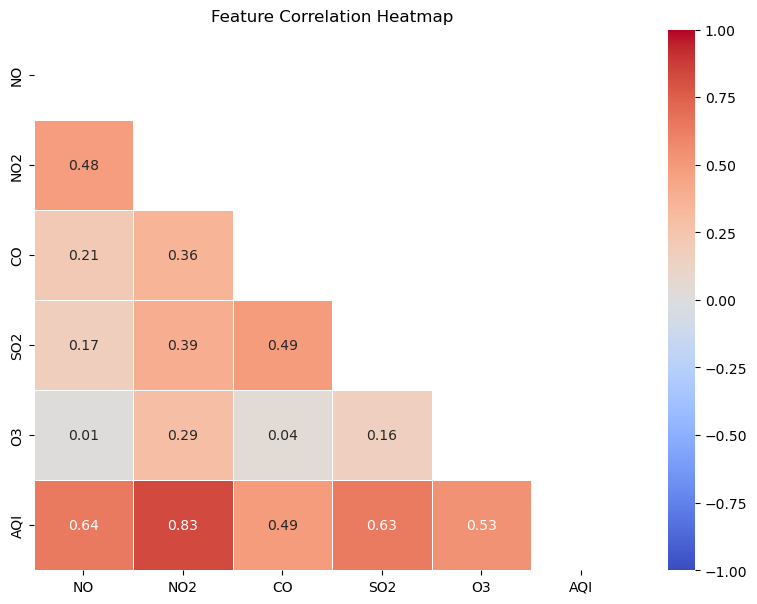

In [13]:
#Import Dependencies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder    
import numpy as np

df = pd.read_csv("city_day_with_aqi.csv")
# Compute synthetic AQI (mean of pollutants)
df["AQI"] = df[["NO", "NO2", "CO", "SO2", "O3"]].mean(axis=1)

# Categorize AQI into levels
df["AQI_Category"] = pd.cut(
    df["AQI"],
    bins=[0, 50, 100, 200, 300, 400, np.inf],
    labels=["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
)

# Prepare features and target
X = df.drop(["AQI", "AQI_Category"], axis=1)
y = df["AQI_Category"]

# Scale and split data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print("✅ Preprocessing Complete")
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Correlation heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
corr = df.select_dtypes(include=[np.number]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.tight_layout()
plt.title("Feature Correlation Heatmap")
plt.show()


✅ Preprocessing Complete
Training Data Shape: (21147, 5)
Testing Data Shape: (5287, 5)
📊 Random Forest Model Evaluation:
Accuracy:  0.995
Precision: 0.994
Recall:    0.995
F1-Score:  0.994

Classification Report:
              precision    recall  f1-score   support

        Good       1.00      1.00      1.00      5138
    Moderate       1.00      0.67      0.80         3
Satisfactory       0.94      0.86      0.90       146

    accuracy                           0.99      5287
   macro avg       0.98      0.84      0.90      5287
weighted avg       0.99      0.99      0.99      5287



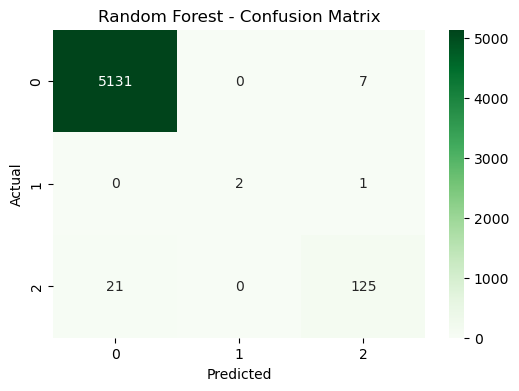

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset (replace path if needed)
df = pd.read_csv("city_day_with_aqi.csv")

# Drop rows with missing target to avoid NaN in y
df = df.dropna(subset=["AQI_Category"]).reset_index(drop=True)

# Prepare features and target
X = df.drop(["AQI", "AQI_Category"], axis=1)
y = df["AQI_Category"]

# Impute missing feature values (mean strategy)
imputer = SimpleImputer(strategy="mean")
X_imputed = imputer.fit_transform(X)

# Scale features (re-using scaler from earlier cell if present, otherwise create new)
try:
    X_scaled = scaler.fit_transform(X_imputed)  # scaler defined in another cell
except NameError:
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imputed)

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print("✅ Preprocessing Complete")
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Train the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion="entropy",
    random_state=42
)
rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test)

# Evaluate
acc = accuracy_score(y_test, y_pred_rf)
prec = precision_score(y_test, y_pred_rf, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_rf, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_rf, average='weighted', zero_division=0)

print("📊 Random Forest Model Evaluation:")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Greens", fmt='g')
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


C:\Users\advai\AppData\Local\Temp\ipykernel_2552\4178924935.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Importance", y="Feature", data=feat_df, palette="viridis")


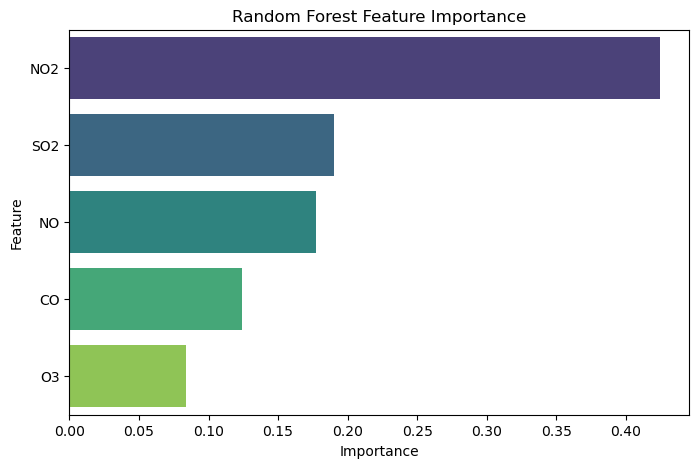

In [18]:
df = pd.read_csv("city_day_with_aqi.csv") 
importances = rf_model.feature_importances_
feature_names = X.columns  # original feature names
feat_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
feat_df = feat_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x="Importance", y="Feature", data=feat_df, palette="viridis")
plt.title("Random Forest Feature Importance")
plt.show()

📊 Logistic Regression Model Evaluation:
Accuracy:  0.999
Precision: 0.999
Recall:    0.999
F1-Score:  0.999

Classification Report:
              precision    recall  f1-score   support

        Good       1.00      1.00      1.00      5138
    Moderate       1.00      1.00      1.00         3
Satisfactory       0.99      0.97      0.98       146

    accuracy                           1.00      5287
   macro avg       1.00      0.99      0.99      5287
weighted avg       1.00      1.00      1.00      5287



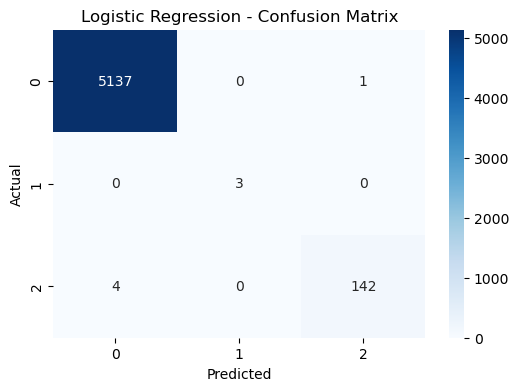

C:\Users\advai\AppData\Local\Temp\ipykernel_2552\2441006044.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Coefficient Magnitude", y="Feature", data=feat_df, palette="coolwarm")


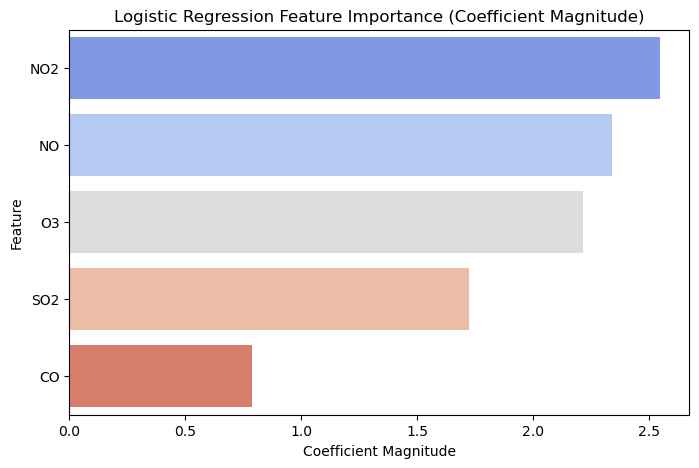

In [19]:
# LOGISTIC REGRESSION - MODEL TRAINING & EVALUATION
# ==========================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv("city_day_with_aqi.csv")

# ⿡ Initialize Logistic Regression Model
log_reg = LogisticRegression(
    solver='lbfgs',      # common solver (you can try 'liblinear' for small datasets)
    max_iter=1000,       # increased to ensure convergence
    random_state=42
)

# ⿢ Train the Model
log_reg.fit(X_train, y_train)

# ⿣ Make Predictions
y_pred_lr = log_reg.predict(X_test)

# ⿤ Evaluate Performance
acc = accuracy_score(y_test, y_pred_lr)
prec = precision_score(y_test, y_pred_lr, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_lr, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_lr, average='weighted', zero_division=0)

print("📊 Logistic Regression Model Evaluation:")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# ⿥ Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt='g')
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ⿦ Optional: Feature Importance Visualization
# (Coefficients represent feature importance in Logistic Regression)
import numpy as np
coef = np.abs(log_reg.coef_[0])  # take absolute value for importance
feature_names = X.columns

feat_df = pd.DataFrame({"Feature": feature_names, "Coefficient Magnitude": coef})
feat_df = feat_df.sort_values(by="Coefficient Magnitude", ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x="Coefficient Magnitude", y="Feature", data=feat_df, palette="coolwarm")
plt.title("Logistic Regression Feature Importance (Coefficient Magnitude)")
plt.show()


In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv("city_day_with_aqi.csv")

# ⿡ Initialize Gaussian Naive Bayes Model
nb_model = GaussianNB()

# ⿢ Train the Model
nb_model.fit(X_train, y_train)

# ⿣ Make Predictions
y_pred_nb = nb_model.predict(X_test)

# ⿤ Evaluate Performance
acc = accuracy_score(y_test, y_pred_nb)
prec = precision_score(y_test, y_pred_nb, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_nb, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_nb, average='weighted', zero_division=0)

print("📊 Gaussian Naive Bayes Model Evaluation:")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

# ⿥ Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Oranges", fmt='g')
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
